Mounted at /content/drive


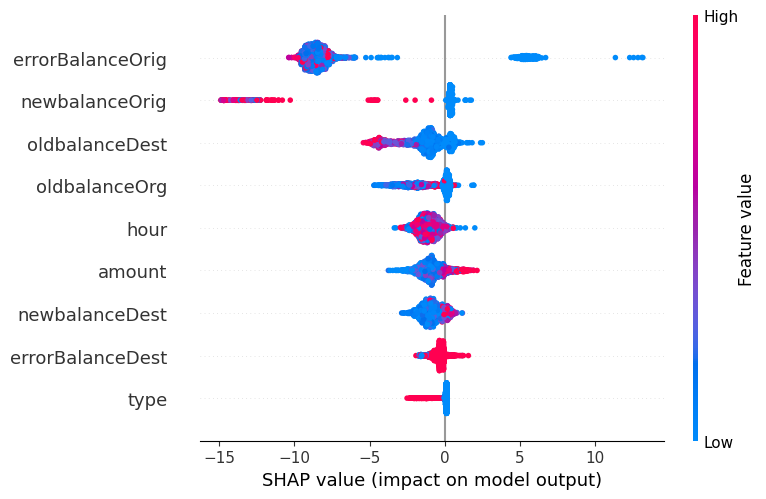

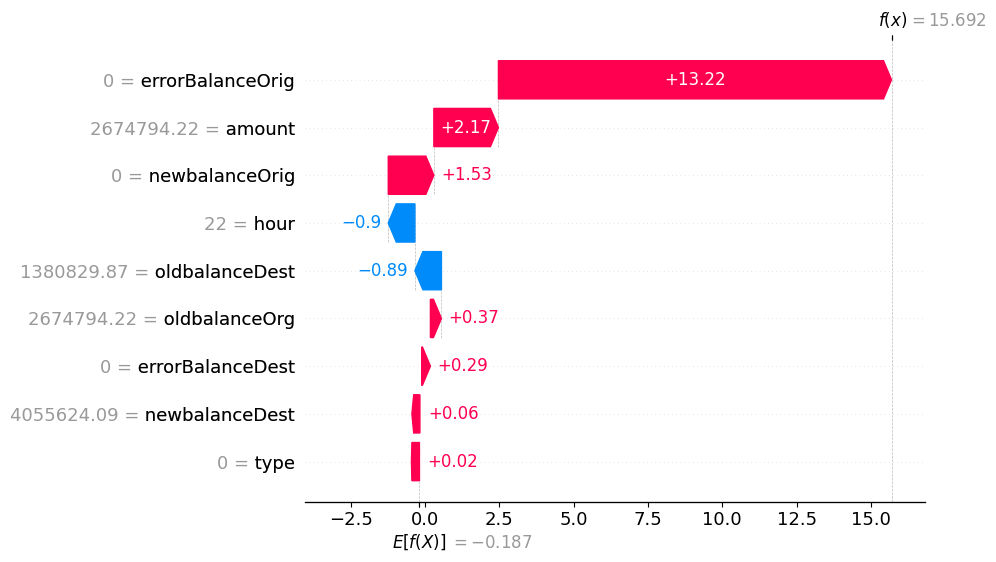

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install shap -q
import shap
import joblib
import matplotlib.pyplot as plt

PATH = "/content/drive/MyDrive/fraud-detection"
X_train, X_test, y_train, y_test = joblib.load(f"{PATH}/data/split.pkl")
model = joblib.load(f"{PATH}/models/fraud_model.pkl")["model"]

explainer = shap.TreeExplainer(model)

# 1. أهم العوامل على مستوى الموديل كله
sample = X_test.sample(2000, random_state=42)
shap.summary_plot(explainer.shap_values(sample), sample, show=False)
plt.savefig(f"{PATH}/figures/07_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. تفسير عملية احتيال واحدة
idx = y_test[y_test == 1].index[0]
sv = explainer(X_test.loc[[idx]])
shap.plots.waterfall(sv[0], show=False)
plt.savefig(f"{PATH}/figures/08_shap_one_case.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

PATH = "/content/drive/MyDrive/fraud-detection"

df = pd.read_csv(f"{PATH}/data/paysim.csv")

demo = pd.concat([
    df[df.isFraud == 1].sample(50, random_state=1),
    df[df.isFraud == 0].sample(950, random_state=1)
]).sample(frac=1, random_state=1)

demo.drop(columns=["isFraud"]).to_csv(f"{PATH}/data/demo.csv", index=False)
print("demo.csv saved ✅", demo.shape)

Mounted at /content/drive
demo.csv saved ✅ (1000, 11)
